# Digital Signal Processing (DSP) — Multi-Domain Signal Processing Project

**Domains Covered:** 1D Mathematical Signals • 1D Real Audio • 2D Digital Images  
**Team Structure:** Modular 6-Student Architecture (`Student 1` through `Student 6`)

---

### Project Architecture & Data Flow
| Role | Domain | Core Task | Key Functions |
| :--- | :--- | :--- | :--- |
| **Student 1** | 1D Mathematical Signal | Composite signal + **manual loop DTFT** (magnitude & phase) | `generate_composite_signal()`, `compute_manual_dtft()` |
| **Student 2** | 1D LTI Systems | Moving Average (`np.convolve` vs. zero-padded FFT) & 1st-order difference eq. | `moving_average_linear()`, `moving_average_freq()`, `first_order_difference_eq()` |
| **Student 3** | 1D Audio Analysis | Load WAV, inject $50/60\text{ Hz}$ hum, identify interference peak in spectrum | `load_audio_mono()`, `add_sinusoidal_interference()`, `analyze_spectrum()` |
| **Student 4** | 1D Audio Filtering | Design & apply 2nd-order IIR Notch filter, export WAV, evaluate attenuation | `design_notch_filter()`, `apply_notch_filter()` |
| **Student 5** | 2D Image Filtering | Grayscale 2D FFT (`fft2` + `fftshift`), ideal circular LPF & HPF masks | `compute_2d_spectrum()`, `create_ideal_circular_masks()`, `apply_2d_mask()` |
| **Student 6** | 2D Image Denoising | Add 2D periodic noise, build 2D Notch mask, reconstruct via `ifft2`, MSE & PSNR | `add_periodic_noise()`, `create_2d_notch_mask()`, `compute_mse_psnr()` |


---
## Section 0: shared configuration & sample data setup


In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal
import cv2

# Global plot styling for clean, presentation-ready figures
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 10

# =============================================================================
# SHARED PROJECT CONFIGURATION
INPUT_WAV_PATH = "lastv (online-audio-converter.com).wav"
NOISY_WAV_PATH = "noisy_speech.wav"       # generated by 3 -> used by 4
FILTERED_WAV_PATH = "filtered_speech.wav" # generated by 4
INPUT_IMAGE_PATH = "WhatsApp Image 2026-11-15 at 2.37.15 PM.jpeg"


def ensure_sample_assets(wav_path: str, img_path: str) -> None:

    if not os.path.exists(wav_path):
        print(f"error occurred while finding audio file: '{wav_path}'")
    else:
        print(f"found existing audio file: '{wav_path}'")
        
    if not os.path.exists(img_path):
        print(f"error occurred while finding image file: '{img_path}'")
    else:
        print(f"found existing image file: '{img_path}'")


ensure_sample_assets(INPUT_WAV_PATH, INPUT_IMAGE_PATH)

found existing audio file: 'lastv (online-audio-converter.com).wav'
found existing image file: 'WhatsApp Image 2026-11-15 at 2.37.15 PM.jpeg'


---
## Student 1 — Mathematical Signal Generation & Manual DTFT

### Core Theory Summary
1. **Discrete-Time Signal $x[n]$:** A sequence indexed by integer sample index $n \in \{0, 1, \dots, N-1\}$, obtained by sampling a continuous signal at sampling rate $f_s$ ($t = n / f_s$).
2. **Normalized Angular Frequency ($\omega$):** Relates physical frequency $f$ (Hz) to discrete-time radians/sample via $\omega = \frac{2\pi f}{f_s} \in [-\pi, \pi]$.
3. **Discrete-Time Fourier Transform (DTFT):** Maps a finite-energy discrete-time sequence $x[n]$ into a continuous $2\pi$-periodic complex function of angular frequency $\omega$:
   $$X(e^{j\omega}) = \sum_{n=0}^{N-1} x[n] e^{-j\omega n}$$
4. **Magnitude & Phase Spectra:** Because $X(e^{j\omega}) = \text{Re}\{X\} + j\,\text{Im}\{X\}$ is complex-valued:
   - **Magnitude Spectrum:** $|X(e^{j\omega})| = \sqrt{\text{Re}^2 + \text{Im}^2}$ shows the strength/energy at each frequency.
   - **Phase Spectrum:** $\angle X(e^{j\omega}) = \operatorname{atan2}(\text{Im}, \text{Re})$ captures the relative timing/shift of each sinusoidal component.

signal length N = 64, frequency grid K = 256
expected peaks at ω1 = ±0.628 rad (100.0 Hz) and ω2 = ±1.759 rad (280.0 Hz)


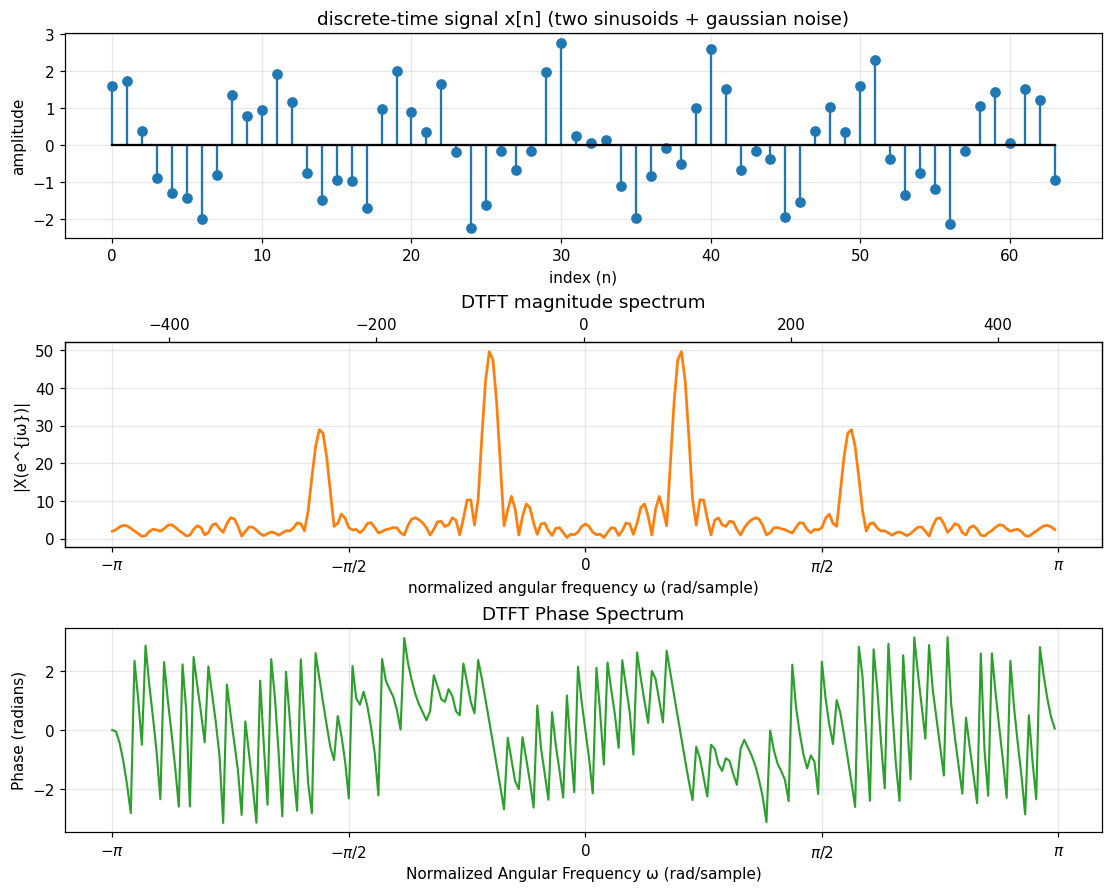

In [2]:
# generate the sinusoidal signal and the noise
def generate_composite_signal(
    fs: float, # 1000 sample/s
    f1: float,
    f2: float,
    noise_std: float = 0.35 , #std deviation
    num_samples: int = 64, # elsample ele h4tghl 3aliha
    a1: float = 1.5, #a-> amplitude
    a2: float = 0.9,
    seed: int = 42,
):
    # Generates a discrete-time signal
    rng = np.random.default_rng(seed) #random number generator
    n = np.arange(num_samples) # create array from 0 to num_samples-1
    t = n / fs # time between each sample: 0.001

    # compine the 3 components: two sinusoids and Gaussian noise
    clean = a1 * np.cos(2 * np.pi * f1 * t) + a2 * np.sin(2 * np.pi * f2 * t)
    noise = rng.normal(loc=0.0, scale=noise_std, size=num_samples) #loc -> mean=0
    x = clean + noise

    return n, x, clean

# DTFT btsa3dna nn2l el el signal mn time domain l frequency domain
def compute_manual_dtft(x: np.ndarray, num_freqs: int):

    N = len(x) # ele homa mn 0~63
    # devide the freq range from -pi to pi into 256 points
    omega = np.linspace(-np.pi, np.pi, num_freqs, endpoint=False) #false-> pi not in range
    X = np.zeros(num_freqs, dtype=np.complex128)

    #calc dtft for each freq point
    for k in range(num_freqs):
        w_k = omega[k]
        acc = 0.0 + 0.0j #accumulator for the DTFT sum

        for n in range(N):
            acc += x[n] * np.exp(-1j * w_k * n)
        X[k] = acc

    return omega, X


def plot_student1_results(n: np.ndarray, x: np.ndarray, omega: np.ndarray, X: np.ndarray, fs: float):
    magnitude = np.abs(X)
    # Zero out tiny numerical noise before computing phase to keep phase plot clean
    X_clean_phase = np.where(magnitude > 1e-10, X, 0.0 + 0.0j)
    phase = np.angle(X_clean_phase)

    fig, axes = plt.subplots(3, 1, figsize=(10, 8), constrained_layout=True)

    # 1. time-domain discrete signal
    axes[0].stem(n, x, linefmt="C0-", markerfmt="C0o", basefmt="k-")
    axes[0].set_title("discrete-time signal x[n] (two sinusoids + gaussian noise)")
    axes[0].set_xlabel("index (n)")
    axes[0].set_ylabel("amplitude")

    # 2. magnitude spectrum
    axes[1].plot(omega, magnitude, color="C1", linewidth=1.8)
    axes[1].set_title("DTFT magnitude spectrum")
    axes[1].set_xlabel("normalized angular frequency ω (rad/sample)")
    axes[1].set_ylabel("|X(e^{jω})|")
    axes[1].set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    axes[1].set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])

    # Secondary top axis in Hz for clarity
    ax_hz = axes[1].twiny()
    ax_hz.set_xlim(-fs / 2, fs / 2)
    ax_hz.grid(False)

    # 3. Phase Spectrum
    axes[2].plot(omega, phase, color="C2", linewidth=1.4)
    axes[2].set_title("DTFT Phase Spectrum")
    axes[2].set_xlabel("Normalized Angular Frequency ω (rad/sample)")
    axes[2].set_ylabel("Phase (radians)")
    axes[2].set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    axes[2].set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])

    plt.show()


# --- 1st Pipeline ---
fs1 = 1000.0 # sampling frequency in Hz
f1_s1, f2_s1 = 100.0, 280.0 # Frequencies of the two sinusoids in Hz

n_s1, x_s1, clean_s1 = generate_composite_signal( fs=fs1, f1=f1_s1, f2=f2_s1)
# n_s1 el samples ele h4tghl 3aliha

omega_s1, X_manual_s1 = compute_manual_dtft(x_s1, num_freqs=256)

print(f"signal length N = {len(x_s1)}, frequency grid K = {len(omega_s1)}")
print(f"expected peaks at ω1 = ±{2*np.pi*f1_s1/fs1:.3f} rad ({f1_s1} Hz) "
      f"and ω2 = ±{2*np.pi*f2_s1/fs1:.3f} rad ({f2_s1} Hz)")

plot_student1_results(n_s1, x_s1, omega_s1, X_manual_s1, fs1)

---
## Student 2 — Convolution, Zero-Padding & Difference Equations

### Core Theory Summary

1. **Linear vs. Circular Convolution (Why Zero-Padding Matters):**
   - **Time-Domain Linear Convolution:** $y[n] = (x * h)[n] = \sum_{k} x[k]h[n-k]$ produces an output of length $L = N + M - 1$.
   - **Frequency-Domain Multiplication:** Multiplying $N$-point DFTs ($X[k] \cdot H[k]$) yields *circular* convolution of length $N$, causing wrap-around distortion at the signal boundaries. Zero-padding both $x[n]$ and $h[n]$ to length $L \ge N + M - 1$ before taking the FFT makes frequency-domain multiplication mathematically identical to linear convolution.
2. **First-Order Difference Equation:** A simple recursive IIR filter smoothing high-frequency noise:
   $$y[n] = \alpha y[n-1] + (1 - \alpha) x[n], \qquad 0 < \alpha < 1$$

input length N = 64, Filter length M = 5, Zero-padded FFT length L = 68
max error (Time Linear Conv vs. Zero-Padded FFT): 5.55e-16
max error without zero-padding (Circular Conv):    0.3694


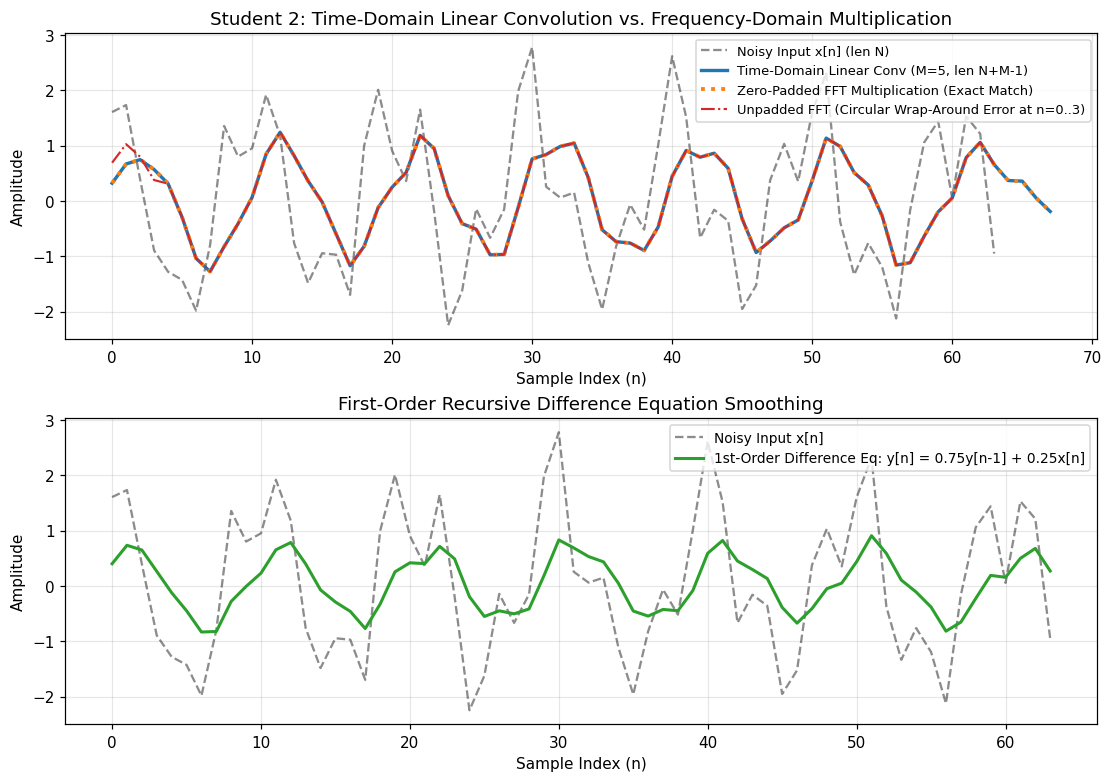

In [3]:
# M_A in time domain
def moving_average_linear(x: np.ndarray, window_size: int ):
    h = np.ones(window_size, dtype=np.float64) / window_size
    y_time_conv = np.convolve(x, h, mode="full")
    return h, y_time_conv

# M_A in freq domain
def moving_average_freq(x: np.ndarray, h: np.ndarray):
    # 1. zero-padded to L = N + M - 1 -> exact linear convolution
    # 2. Unpadded length N -> circular convolution (demonstrates wrap-around error)
    
    N = len(x)
    M = len(h)
    L = N + M - 1

    # zero-padded linear convolution via FFT
    X_pad = np.fft.fft(x, n=L)
    H_pad = np.fft.fft(h, n=L)
    y_freq_conv = np.real(np.fft.ifft(X_pad * H_pad))

    # Unpadded circular convolution via FFT (for comparison)
    X_circ = np.fft.fft(x, n=N)
    H_circ = np.fft.fft(h, n=N)
    y_freq_circular = np.real(np.fft.ifft(X_circ * H_circ))

    return y_freq_conv, y_freq_circular

# first-order difference equation
def first_order_difference_eq(x: np.ndarray, alpha: float = 0.75):

    y = np.zeros_like(x, dtype=np.float64)
    prev_y = 0.0
    for n in range(len(x)):
        y[n] = alpha * prev_y + (1.0 - alpha) * x[n]
        prev_y = y[n]
    return y


def plot_student2_results(
    x: np.ndarray,
    y_time: np.ndarray,
    y_freq_conv: np.ndarray,
    y_freq_circular: np.ndarray,
    y_diff: np.ndarray,
    M: int,
    alpha: float,
):
    """Plots time vs. zero-padded FFT convolution, circular wrap-around artifact, and 1st-order IIR."""
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)

    # Panel 1: Time-domain linear convolution vs. Zero-padded FFT vs. Unpadded Circular FFT
    n_orig = np.arange(len(x))
    n_full = np.arange(len(y_time))
    axes[0].plot(n_orig, x, "k--", alpha=0.45, label="Noisy Input x[n] (len N)")
    axes[0].plot(n_full, y_time, "C0-", linewidth=2.2, label=f"Time-Domain Linear Conv (M={M}, len N+M-1)")
    axes[0].plot(n_full, y_freq_conv, "C1:", linewidth=2.5, label="Zero-Padded FFT Multiplication (Exact Match)")
    axes[0].plot(n_orig, y_freq_circular, "C3-.", linewidth=1.4, label="Unpadded FFT (Circular Wrap-Around Error at n=0..3)")
    axes[0].set_title("Student 2: Time-Domain Linear Convolution vs. Frequency-Domain Multiplication")
    axes[0].set_xlabel("Sample Index (n)")
    axes[0].set_ylabel("Amplitude")
    axes[0].legend(loc="upper right", fontsize=8.5)

    # Panel 2: First-order difference equation output
    axes[1].plot(n_orig, x, "k--", alpha=0.45, label="Noisy Input x[n]")
    axes[1].plot(n_orig, y_diff, "C2-", linewidth=2.0, label=f"1st-Order Difference Eq: y[n] = {alpha}y[n-1] + {1-alpha:.2f}x[n]")
    axes[1].set_title("First-Order Recursive Difference Equation Smoothing")
    axes[1].set_xlabel("Sample Index (n)")
    axes[1].set_ylabel("Amplitude")
    axes[1].legend(loc="upper right", fontsize=9)

    plt.show()


# --- 2 Pipeline (using noisy signal x_s1) ---
M_ma = 5
alpha_de = 0.75
h_ma, y_time_conv = moving_average_linear(x_s1, window_size=M_ma)
y_freq_conv, y_freq_circ_s2 = moving_average_freq(x_s1, h_ma)
y_diff_s2 = first_order_difference_eq(x_s1, alpha=alpha_de)

max_diff_padded = np.max(np.abs(y_time_conv - y_freq_conv))
boundary_circ_err = np.max(np.abs(y_time_conv[:len(x_s1)] - y_freq_circ_s2))
print(f"input length N = {len(x_s1)}, Filter length M = {M_ma}, Zero-padded FFT length L = {len(y_time_conv)}")
print(f"max error (Time Linear Conv vs. Zero-Padded FFT): {max_diff_padded:.2e}")
print(f"max error without zero-padding (Circular Conv):    {boundary_circ_err:.4f}")

plot_student2_results(x_s1, y_time_conv, y_freq_conv, y_freq_circ_s2, y_diff_s2, M_ma, alpha_de)

---
## Student 3 — Audio Analysis & Sinusoidal Interference Injection

loaded 'D:\khaled\projects\DSP\lastv (online-audio-converter.com).wav' | fs = 44100 Hz | Nyquist = 22050 Hz | Duration = 3.58 s
injected 50.0 Hz hum -> Identified spectral peak at 50.06 Hz
saved noisy audio to 'noisy_speech.wav'


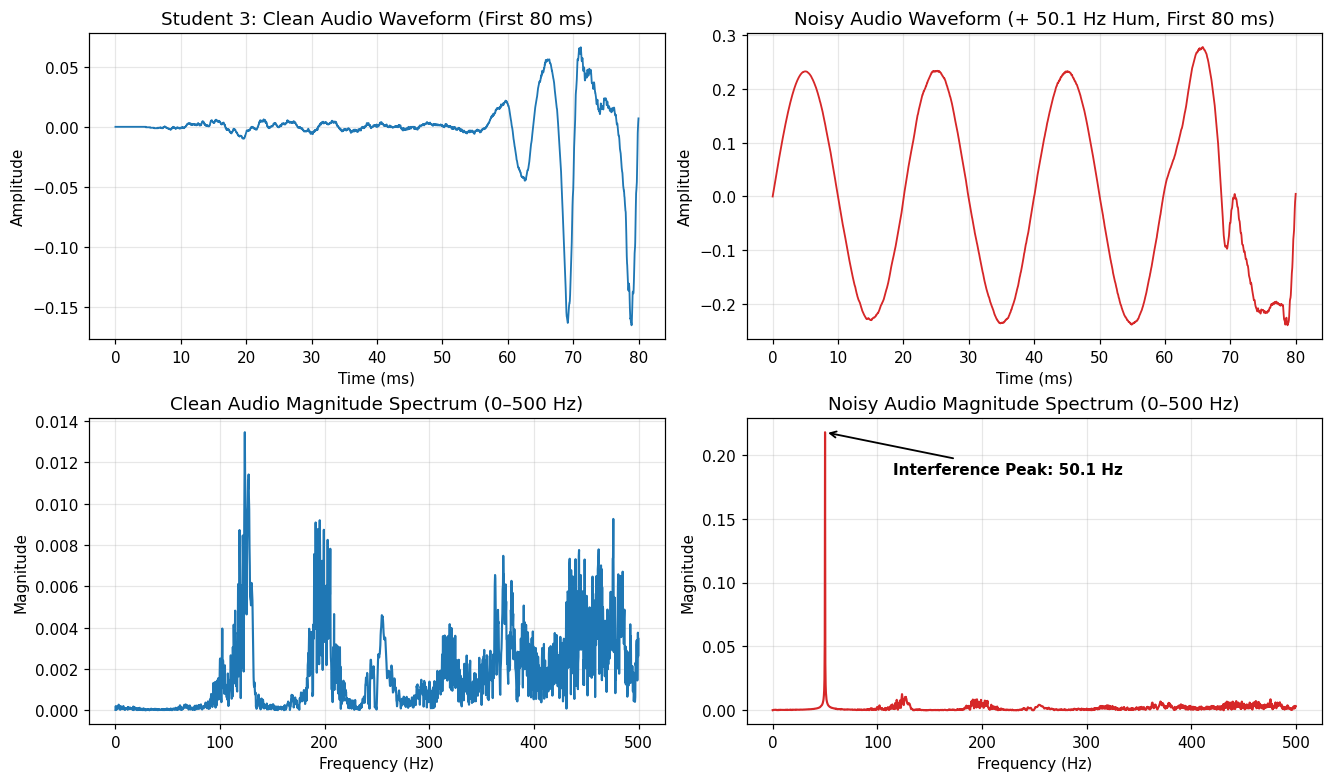

In [4]:
def load_audio_mono(filepath: str):
    # load WAV file and check if stereo, convert to mono if needed
    fs, data = wavfile.read(filepath)
    if data.ndim > 1: 
        data = np.mean(data, axis=1)

    # normalizes [-1, 1]
    if np.issubdtype(data.dtype, np.integer):
        max_val = np.iinfo(data.dtype).max
        audio = data.astype(np.float64) / max_val
    else:
        audio = data.astype(np.float64)
        peak = np.max(np.abs(audio))
        if peak > 0:
            audio = audio / peak
    return fs, audio

#add noise
def add_sinusoidal_interference(audio: np.ndarray, fs: int, f_noise: float , amplitude: float = 0.25):

    n = np.arange(len(audio))
    interference = amplitude * np.sin(2 * np.pi * f_noise * n / fs)
    noisy = audio + interference
    peak = np.max(np.abs(noisy))

    # to keep range within [-1, 1]
    if peak > 0.99:
        noisy = noisy / peak * 0.95

    return noisy, interference

def compute_single_sided_spectrum(signal_data: np.ndarray, fs: int):

    N = len(signal_data)
    fft_vals = np.fft.rfft(signal_data)
    freqs = np.fft.rfftfreq(N, d=1.0 / fs)
    mag_linear = np.abs(fft_vals) / N
    mag_linear[1:-1] *= 2.0

    return freqs, mag_linear

def plot_student3_results(
    clean_audio: np.ndarray,
    noisy_audio: np.ndarray,
    fs: int,
    detected_freq: float,
):
    t = np.arange(len(clean_audio)) / fs
    zoom_samples = min(int(0.08 * fs), len(clean_audio))  # First 80 ms to see 60 Hz cycles clearly

    freqs, mag_clean = compute_single_sided_spectrum(clean_audio, fs)
    _, mag_noisy = compute_single_sided_spectrum(noisy_audio, fs)

    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)

    # Top-left: Clean Waveform (zoomed)
    axes[0, 0].plot(t[:zoom_samples] * 1000, clean_audio[:zoom_samples], color="C0", linewidth=1.2)
    axes[0, 0].set_title("Student 3: Clean Audio Waveform (First 80 ms)")
    axes[0, 0].set_xlabel("Time (ms)")
    axes[0, 0].set_ylabel("Amplitude")

    # Top-right: Noisy Waveform (zoomed)
    axes[0, 1].plot(t[:zoom_samples] * 1000, noisy_audio[:zoom_samples], color="C3", linewidth=1.2)
    axes[0, 1].set_title(f"Noisy Audio Waveform (+ {detected_freq:.1f} Hz Hum, First 80 ms)")
    axes[0, 1].set_xlabel("Time (ms)")
    axes[0, 1].set_ylabel("Amplitude")

    # Bottom-left: Clean Spectrum (0 - 500 Hz)
    mask_500 = freqs <= 500.0
    axes[1, 0].plot(freqs[mask_500], mag_clean[mask_500], color="C0", linewidth=1.4)
    axes[1, 0].set_title("Clean Audio Magnitude Spectrum (0–500 Hz)")
    axes[1, 0].set_xlabel("Frequency (Hz)")
    axes[1, 0].set_ylabel("Magnitude")

    # Bottom-right: Noisy Spectrum (0 - 500 Hz) with peak annotation
    axes[1, 1].plot(freqs[mask_500], mag_noisy[mask_500], color="C3", linewidth=1.4)
    peak_idx = np.argmin(np.abs(freqs - detected_freq))
    axes[1, 1].annotate(
        f"Interference Peak: {detected_freq:.1f} Hz",
        xy=(detected_freq, mag_noisy[peak_idx]),
        xytext=(detected_freq + 65, mag_noisy[peak_idx] * 0.85),
        arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
        fontweight="bold",
    )
    axes[1, 1].set_title("Noisy Audio Magnitude Spectrum (0–500 Hz)")
    axes[1, 1].set_xlabel("Frequency (Hz)")
    axes[1, 1].set_ylabel("Magnitude")

    plt.show()


# --- 3 Pipeline ---
freq__HZ = 50.0

fs_audio, clean_audio_s3 = load_audio_mono(INPUT_WAV_PATH)
noisy_audio_s3, hum_tone_s3 = add_sinusoidal_interference(
    clean_audio_s3, fs_audio, f_noise=freq__HZ, amplitude=0.25
)

# Save noisy WAV for next teammate
wavfile.write(NOISY_WAV_PATH, fs_audio, np.int16(noisy_audio_s3 * 32767))

# identify the added interference frequency
freqs_s3, mag_clean_s3 = compute_single_sided_spectrum(clean_audio_s3, fs_audio)
_, mag_noisy_s3 = compute_single_sided_spectrum(noisy_audio_s3, fs_audio)
detected_hum_hz = freqs_s3[np.argmax(mag_noisy_s3 - mag_clean_s3)]

print(f"loaded '{INPUT_WAV_PATH}' | fs = {fs_audio} Hz | Nyquist = {fs_audio/2:.0f} Hz | Duration = {len(clean_audio_s3)/fs_audio:.2f} s")
print(f"injected {freq__HZ:.1f} Hz hum -> Identified spectral peak at {detected_hum_hz:.2f} Hz")
print(f"saved noisy audio to '{NOISY_WAV_PATH}'")

plot_student3_results(clean_audio_s3, noisy_audio_s3, fs_audio, detected_hum_hz)

---
## Student 4 — Audio Filtering via Second-Order IIR Notch Filter

### Core Theory Summary
1. **Second-Order IIR Notch Filter Transfer Function:** To reject a narrowband interference frequency $\omega_0 = \frac{2\pi f_0}{f_s}$ while preserving surrounding speech frequencies, we place a pair of **complex-conjugate zeros** directly on the unit circle at $z = e^{\pm j\omega_0}$ and a pair of **complex-conjugate poles** just inside the unit circle at $z = r e^{\pm j\omega_0}$ ($0 < r < 1$):
   $$H(z) = G \cdot \frac{1 - 2\cos(\omega_0)z^{-1} + z^{-2}}{1 - 2r\cos(\omega_0)z^{-1} + r^2 z^{-2}}$$
2. **Filter Coefficients:**
   - Feedforward (numerator): $b = G \cdot [1,\; -2\cos(\omega_0),\; 1]$
   - Feedback (denominator): $a = [1,\; -2r\cos(\omega_0),\; r^2]$
   - DC Gain Normalization: $G = \frac{1 - 2r\cos(\omega_0) + r^2}{2 - 2\cos(\omega_0)}$ ensures $|H(e^{j0})| = 1$.
3. **FIR vs. IIR & Stability:** Because $a_1, a_2 \ne 0$, the output depends recursively on past outputs (Infinite Impulse Response — IIR). Since $0 < r < 1$, both poles lie strictly inside the unit circle ($|p_{1,2}| = r < 1$), guaranteeing BIBO stability. Values of $r$ closer to $1$ produce a narrower notch.

notch Frequency f0 = 50.0 Hz (ω0 = 0.00712 rad/sample), Pole radius r = 0.9993
feedforward b = [ 0.9993  -1.99855  0.9993 ]
feedback    a = [ 1.       -1.998549  0.9986  ]
pole magnitudes |p1,2| = [0.9993 0.9993] (< 1 -> BIBO Stable)
interference attenuation at 50.0 Hz: -40.29 dB
approx. notch bandwidth: 9.8 Hz
passband gain at 200/1000/5000 Hz (dB): [-0.01 -0.   -0.  ]
saved cleaned audio to 'filtered_speech.wav'


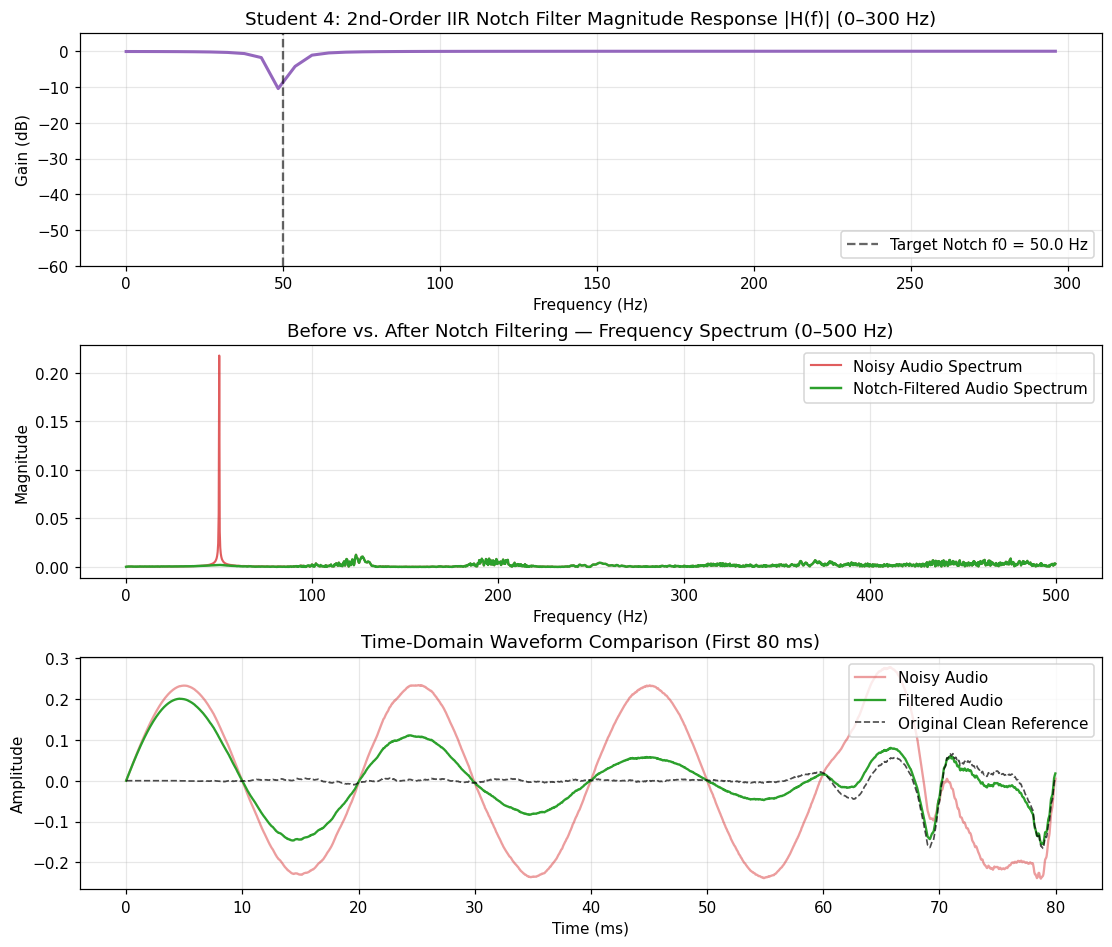

In [8]:
def design_notch_filter(f0: float, fs: float, r: float ):

    w0 = 2.0 * np.pi * f0 / fs
    cos_w0 = np.cos(w0)

    # numerator & denominator
    b_raw = np.array([1.0, -2.0 * cos_w0, 1.0], dtype=np.float64)
    a = np.array([1.0, -2.0 * r * cos_w0, r ** 2], dtype=np.float64)

    gain_nyq = (1.0 + 2.0 * r * cos_w0 + r ** 2) / (2.0 + 2.0 * cos_w0)
    b = gain_nyq * b_raw
    return b, a, w0


def apply_notch_filter(noisy_audio: np.ndarray, b: np.ndarray, a: np.ndarray):

    filtered = signal.lfilter(b, a, noisy_audio)
    return filtered


def plot_student4_results(
    b: np.ndarray,
    a: np.ndarray,
    noisy_audio: np.ndarray,
    filtered_audio: np.ndarray,
    clean_audio: np.ndarray,
    fs: int,
    f0: float,
):
    """Plots Notch frequency response |H(f)|, before/after spectrum overlay, and time comparison."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), constrained_layout=True)

    # 1. Notch Filter Frequency Magnitude Response
    w_resp, h_resp = signal.freqz(b, a, worN=4096, fs=fs)
    mask_zoom = w_resp <= 300.0
    axes[0].plot(w_resp[mask_zoom], 20 * np.log10(np.abs(h_resp[mask_zoom]) + 1e-12), color="C4", linewidth=2.0)
    axes[0].axvline(f0, color="k", linestyle="--", alpha=0.6, label=f"Target Notch f0 = {f0:.1f} Hz")
    axes[0].set_title("Student 4: 2nd-Order IIR Notch Filter Magnitude Response |H(f)| (0–300 Hz)")
    axes[0].set_xlabel("Frequency (Hz)")
    axes[0].set_ylabel("Gain (dB)")
    axes[0].set_ylim([-60, 5])
    axes[0].legend()

    # 2. Spectrum Overlay: Noisy vs. Filtered
    freqs, mag_noisy = compute_single_sided_spectrum(noisy_audio, fs)
    _, mag_filt = compute_single_sided_spectrum(filtered_audio, fs)
    mask_500 = freqs <= 500.0
    axes[1].plot(freqs[mask_500], mag_noisy[mask_500], color="C3", alpha=0.75, linewidth=1.4, label="Noisy Audio Spectrum")
    axes[1].plot(freqs[mask_500], mag_filt[mask_500], color="C2", linewidth=1.6, label="Notch-Filtered Audio Spectrum")
    axes[1].set_title("Before vs. After Notch Filtering — Frequency Spectrum (0–500 Hz)")
    axes[1].set_xlabel("Frequency (Hz)")
    axes[1].set_ylabel("Magnitude")
    axes[1].legend()

    # 3. Time-Domain Comparison (zoomed 80 ms)
    t = np.arange(len(clean_audio)) / fs
    zoom = min(int(0.08 * fs), len(clean_audio))
    axes[2].plot(t[:zoom] * 1000, noisy_audio[:zoom], color="C3", alpha=0.45, label="Noisy Audio")
    axes[2].plot(t[:zoom] * 1000, filtered_audio[:zoom], color="C2", linewidth=1.5, label="Filtered Audio")
    axes[2].plot(t[:zoom] * 1000, clean_audio[:zoom], "k--", alpha=0.7, linewidth=1.1, label="Original Clean Reference")
    axes[2].set_title("Time-Domain Waveform Comparison (First 80 ms)")
    axes[2].set_xlabel("Time (ms)")
    axes[2].set_ylabel("Amplitude")
    axes[2].legend(loc="upper right")

    plt.show()


# --- 4 Pipeline ---
fs_s4, noisy_loaded_s4 = load_audio_mono(NOISY_WAV_PATH)
pole_radius = 0.9993
b_notch, a_notch, w0_notch = design_notch_filter(f0=freq__HZ, fs=fs_s4, r=pole_radius)
filtered_audio_s4 = apply_notch_filter(noisy_loaded_s4, b_notch, a_notch)

# Save filtered WAV output
wavfile.write(FILTERED_WAV_PATH, fs_s4, np.int16(np.clip(filtered_audio_s4, -1.0, 1.0) * 32767))

# Measure tone attenuation at HUM_FREQ_HZ
freqs_s4, mag_n_s4 = compute_single_sided_spectrum(noisy_loaded_s4, fs_s4)
_, mag_f_s4  = compute_single_sided_spectrum(filtered_audio_s4, fs_s4)
idx_f0 = np.argmin(np.abs(freqs_s4 - freq__HZ))
attenuation_db = 20 * np.log10((mag_f_s4[idx_f0] + 1e-12) / (mag_n_s4[idx_f0] + 1e-12))

print(f"notch Frequency f0 = {freq__HZ} Hz (ω0 = {w0_notch:.5f} rad/sample), Pole radius r = {pole_radius}")
print(f"feedforward b = {np.round(b_notch, 6)}")
print(f"feedback    a = {np.round(a_notch, 6)}")
print(f"pole magnitudes |p1,2| = {np.abs(np.roots(a_notch))} (< 1 -> BIBO Stable)")
print(f"interference attenuation at {freq__HZ} Hz: {attenuation_db:.2f} dB")
print(f"approx. notch bandwidth: {(1 - pole_radius) * fs_s4 / np.pi:.1f} Hz")
_, h_chk = signal.freqz(b_notch, a_notch, worN=[2*np.pi*f/fs_s4 for f in (200, 1000, 5000)])
print(f"passband gain at 200/1000/5000 Hz (dB): {np.round(20*np.log10(np.abs(h_chk)), 2)}")
print(f"saved cleaned audio to '{FILTERED_WAV_PATH}'")

plot_student4_results(b_notch, a_notch, noisy_loaded_s4, filtered_audio_s4, clean_audio_s3, fs_s4, freq__HZ)

---
## Student 5 — 2D Fourier Transform & Ideal Spatial Frequency Filtering

### Core Theory Summary
1. **2D Discrete Fourier Transform (2D DFT):** Decomposes a grayscale image $I(x,y)$ of size $M \times N$ into 2D complex exponentials representing horizontal and vertical spatial frequencies $(u, v)$:
   $$F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} I(x, y) e^{-j 2\pi (ux/M + vy/N)}$$
2. **Spectrum Centering (`fftshift`) & Log Scaling:** `np.fft.fftshift` moves the zero-frequency (DC) component—average image brightness—from the top-left corner to the center $(M/2, N/2)$. Because dynamic range spans orders of magnitude, we visualize $\log(1 + |F(u, v)|)$.
3. **Ideal Circular Low-Pass vs. High-Pass Filters:** Defining Euclidean distance from the center $D(u, v) = \sqrt{(u - M/2)^2 + (v - N/2)^2}$ and cutoff radius $D_0$:
   - **Ideal Low-Pass Filter (LPF):** $H_{\text{LP}}(u, v) = 1$ if $D(u, v) \le D_0$ else $0$. Preserves smooth brightness gradients and blurs fine edges (exhibits slight Gibbs ringing due to sharp frequency cutoff).
   - **Ideal High-Pass Filter (HPF):** $H_{\text{HP}}(u, v) = 1 - H_{\text{LP}}(u, v)$. Removes smooth regions ($D \le D_0$) and extracts sharp edges and fine textures.

[Student 5] Loaded image shape = (1430, 1170) | Ideal circular cutoff D0 = 28.0 px


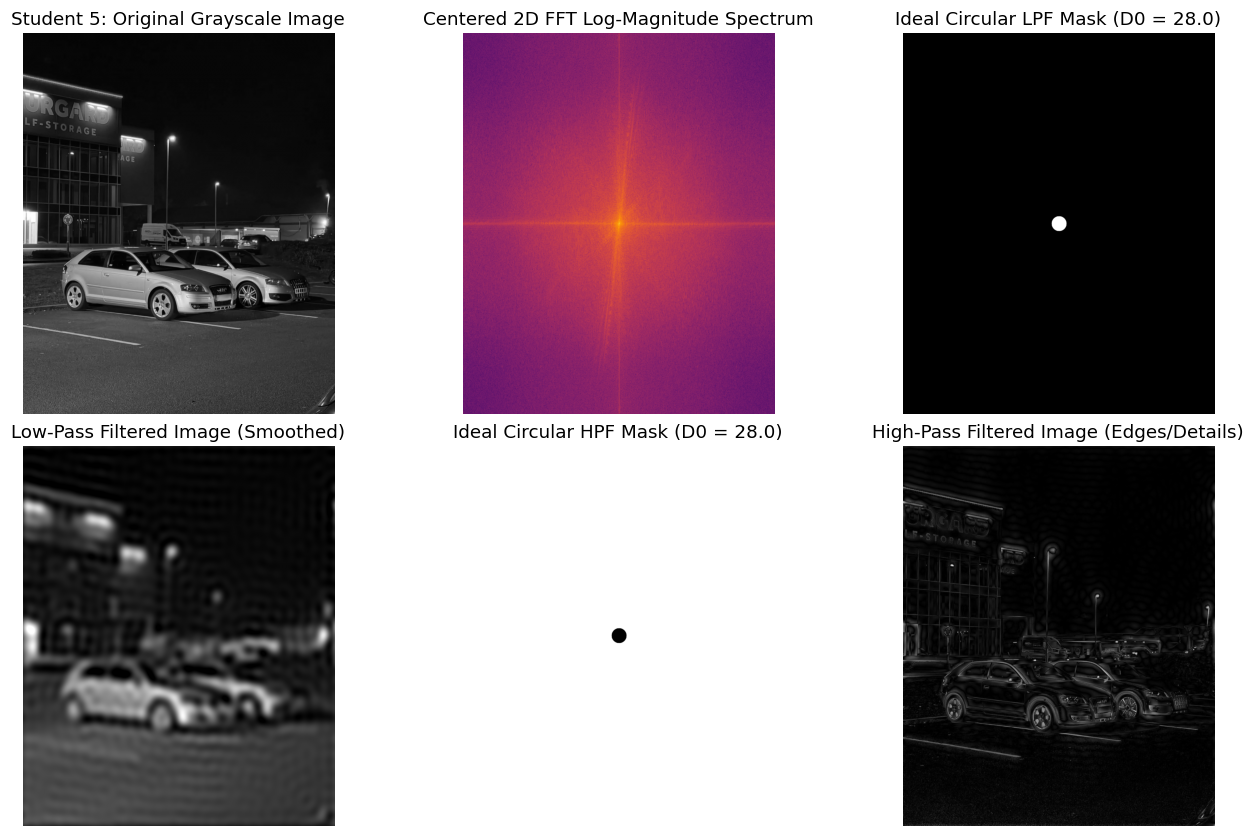

In [6]:
def load_grayscale_image(filepath: str) -> np.ndarray:
    """Loads an image in grayscale as float64."""
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not load image at '{filepath}'.")
    return img.astype(np.float64)


def compute_2d_spectrum(img: np.ndarray):
    """Computes centered 2D FFT and its log-magnitude spectrum for visualization."""
    f_transform = np.fft.fft2(img)
    f_shift = np.fft.fftshift(f_transform)
    log_magnitude = np.log1p(np.abs(f_shift))
    return f_shift, log_magnitude


def create_ideal_circular_masks(shape: tuple, cutoff_radius: float):
    """Constructs ideal circular Low-Pass (LPF) and High-Pass (HPF) frequency masks."""
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2
    u = np.arange(rows) - crow
    v = np.arange(cols) - ccol
    U, V = np.meshgrid(u, v, indexing="ij")
    D = np.sqrt(U ** 2 + V ** 2)

    lpf_mask = (D <= cutoff_radius).astype(np.float64)
    hpf_mask = (D > cutoff_radius).astype(np.float64)
    return lpf_mask, hpf_mask


def apply_2d_frequency_mask(f_shift: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Applies a 2D frequency mask and reconstructs the spatial image via inverse 2D FFT."""
    filtered_shift = f_shift * mask
    img_back = np.real(np.fft.ifft2(np.fft.ifftshift(filtered_shift)))
    return img_back


def plot_student5_results(
    img: np.ndarray,
    log_spec: np.ndarray,
    lpf_mask: np.ndarray,
    img_lpf: np.ndarray,
    hpf_mask: np.ndarray,
    img_hpf: np.ndarray,
    d0: float,
):
    """Displays original image, 2D log spectrum, ideal LPF/HPF masks, and filtered images."""
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), constrained_layout=True)

    axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title("Student 5: Original Grayscale Image")

    axes[0, 1].imshow(log_spec, cmap="inferno")
    axes[0, 1].set_title("Centered 2D FFT Log-Magnitude Spectrum")

    axes[0, 2].imshow(lpf_mask, cmap="gray")
    axes[0, 2].set_title(f"Ideal Circular LPF Mask (D0 = {d0})")

    axes[1, 0].imshow(np.clip(img_lpf, 0, 255), cmap="gray", vmin=0, vmax=255)
    axes[1, 0].set_title("Low-Pass Filtered Image (Smoothed)")

    axes[1, 1].imshow(hpf_mask, cmap="gray")
    axes[1, 1].set_title(f"Ideal Circular HPF Mask (D0 = {d0})")

    # Enhance contrast of HPF output for clear edge visibility
    hpf_display = np.abs(img_hpf)
    hpf_display = hpf_display / (np.max(hpf_display) + 1e-12) * 255.0
    axes[1, 2].imshow(hpf_display, cmap="gray", vmin=0, vmax=255)
    axes[1, 2].set_title("High-Pass Filtered Image (Edges/Details)")

    for ax in axes.flat:
        ax.axis("off")

    plt.show()


# --- Execute Student 5 Pipeline ---
img_s5 = load_grayscale_image(INPUT_IMAGE_PATH)
f_shift_s5, log_spec_s5 = compute_2d_spectrum(img_s5)
cutoff_d0 = 28.0
lpf_mask_s5, hpf_mask_s5 = create_ideal_circular_masks(img_s5.shape, cutoff_radius=cutoff_d0)

img_lpf_s5 = apply_2d_frequency_mask(f_shift_s5, lpf_mask_s5)
img_hpf_s5 = apply_2d_frequency_mask(f_shift_s5, hpf_mask_s5)

print(f"[Student 5] Loaded image shape = {img_s5.shape} | Ideal circular cutoff D0 = {cutoff_d0} px")
plot_student5_results(img_s5, log_spec_s5, lpf_mask_s5, img_lpf_s5, hpf_mask_s5, img_hpf_s5, cutoff_d0)

---
## Student 6 — Periodic Image Noise Removal & Quality Evaluation (MSE & PSNR)

### Core Theory Summary
1. **2D Periodic Sinusoidal Noise:** Adding a 2D sinusoid $n(x, y) = A \sin\left(2\pi \left(\frac{u_0 x}{M} + \frac{v_0 y}{N}\right)\right)$ creates repetitive stripe patterns in the spatial domain. In the centered 2D Fourier spectrum, this single real sinusoid appears as **two bright conjugate impulse peaks** located symmetrically around the DC center at:
   $$(c_y + u_0,\; c_x + v_0) \quad \text{and} \quad (c_y - u_0,\; c_x - v_0)$$
2. **2D Notch Reject Mask & Inverse FFT:** Setting small circular neighborhoods of radius $r_{\text{notch}}$ around both conjugate peaks to $0$ eliminates the periodic stripes while preserving almost all surrounding image frequencies. Applying `ifftshift` followed by `ifft2` reconstructs the clean spatial image.
3. **Objective Quality Metrics (MSE & PSNR):** Comparing restored image $\hat{I}(x, y)$ against ground-truth $I(x, y)$ (with $\text{MAX}_I = 255$):
   $$\text{MSE} = \frac{1}{MN} \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} \left[I(x, y) - \hat{I}(x, y)\right]^2, \qquad \text{PSNR} = 10 \log_{10}\left(\frac{255^2}{\text{MSE}}\right) \text{ dB}$$

[Student 6] Added periodic noise at frequency offsets (u0, v0) = (±24, ±32)
[Student 6] Noisy Image    -> MSE =   784.30 | PSNR =  19.19 dB
[Student 6] Restored Image -> MSE =    75.95 | PSNR =  29.33 dB (+10.14 dB gain)


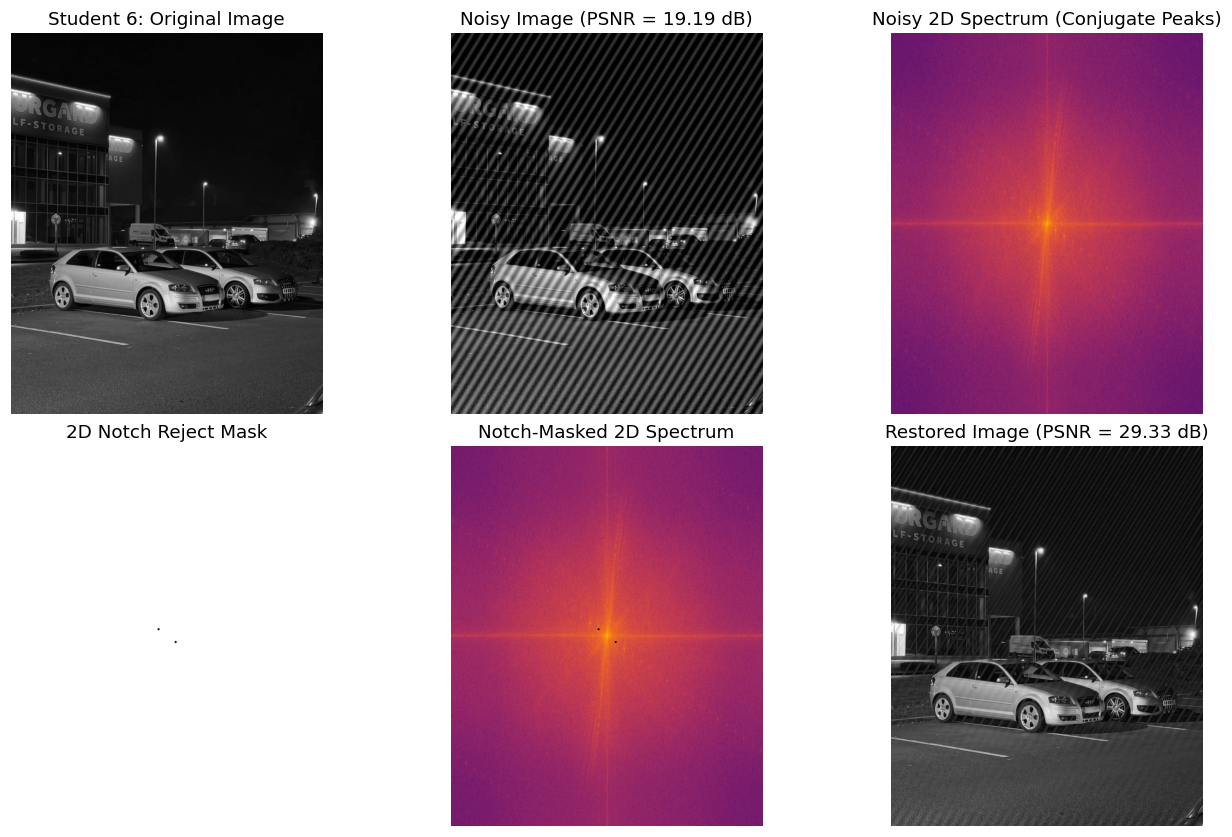

In [7]:
def add_periodic_image_noise(img: np.ndarray, u0: int = 24, v0: int = 32, amplitude: float = 45.0):
    """
    Adds 2D periodic sinusoidal noise with spatial frequency offsets (u0, v0) cycles/image.
    Produces symmetric spectral spikes at (M/2 ± u0, N/2 ± v0) in the centered 2D FFT.
    """
    M, N = img.shape
    x = np.arange(M)[:, None]
    y = np.arange(N)[None, :]
    noise = amplitude * np.sin(2.0 * np.pi * (u0 * x / M + v0 * y / N))
    noisy_img = np.clip(img + noise, 0.0, 255.0)
    return noisy_img, noise


def create_2d_notch_mask(shape: tuple, u0: int, v0: int, notch_radius: float = 4.0) -> np.ndarray:
    """Creates a 2D Notch Reject mask zeroing out the two conjugate noise peaks at (cy ± u0, cx ± v0)."""
    M, N = shape
    cy, cx = M // 2, N // 2
    Y, X = np.ogrid[:M, :N]

    # Two symmetric conjugate impulse locations
    p1 = (cy + u0, cx + v0)
    p2 = (cy - u0, cx - v0)

    dist1 = np.sqrt((Y - p1[0]) ** 2 + (X - p1[1]) ** 2)
    dist2 = np.sqrt((Y - p2[0]) ** 2 + (X - p2[1]) ** 2)

    mask = np.ones((M, N), dtype=np.float64)
    mask[(dist1 <= notch_radius) | (dist2 <= notch_radius)] = 0.0
    return mask


def compute_mse_psnr(original: np.ndarray, test_img: np.ndarray, max_pixel: float = 255.0):
    """Calculates Mean Squared Error (MSE) and Peak Signal-to-Noise Ratio (PSNR in dB)."""
    mse = np.mean((original - test_img) ** 2)
    if mse == 0:
        return 0.0, float("inf")
    psnr = 10.0 * np.log10((max_pixel ** 2) / mse)
    return mse, psnr


def plot_student6_results(
    orig: np.ndarray,
    noisy: np.ndarray,
    log_noisy_spec: np.ndarray,
    notch_mask: np.ndarray,
    log_masked_spec: np.ndarray,
    restored: np.ndarray,
    psnr_noisy: float,
    psnr_restored: float,
):
    """Plots the complete 6-panel periodic noise removal & spectral restoration pipeline."""
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), constrained_layout=True)

    axes[0, 0].imshow(orig, cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title("Student 6: Original Image")

    axes[0, 1].imshow(noisy, cmap="gray", vmin=0, vmax=255)
    axes[0, 1].set_title(f"Noisy Image (PSNR = {psnr_noisy:.2f} dB)")

    axes[0, 2].imshow(log_noisy_spec, cmap="inferno")
    axes[0, 2].set_title("Noisy 2D Spectrum (Conjugate Peaks)")

    axes[1, 0].imshow(notch_mask, cmap="gray")
    axes[1, 0].set_title("2D Notch Reject Mask")

    axes[1, 1].imshow(log_masked_spec, cmap="inferno")
    axes[1, 1].set_title("Notch-Masked 2D Spectrum")

    axes[1, 2].imshow(restored, cmap="gray", vmin=0, vmax=255)
    axes[1, 2].set_title(f"Restored Image (PSNR = {psnr_restored:.2f} dB)")

    for ax in axes.flat:
        ax.axis("off")

    plt.show()


# --- Execute Student 6 Pipeline (using Student 5's grayscale image img_s5) ---
u0_noise, v0_noise = 24, 32
noisy_img_s6, _ = add_periodic_image_noise(img_s5, u0=u0_noise, v0=v0_noise, amplitude=45.0)

f_shift_noisy_s6, log_noisy_spec_s6 = compute_2d_spectrum(noisy_img_s6)
notch_mask_s6 = create_2d_notch_mask(img_s5.shape, u0=u0_noise, v0=v0_noise, notch_radius=4.0)

# Apply Notch mask and reconstruct spatial image via inverse 2D FFT
f_shift_restored_s6 = f_shift_noisy_s6 * notch_mask_s6
log_masked_spec_s6 = np.log1p(np.abs(f_shift_restored_s6))
restored_img_s6 = np.clip(np.real(np.fft.ifft2(np.fft.ifftshift(f_shift_restored_s6))), 0.0, 255.0)

# Evaluate MSE and PSNR before and after restoration
mse_noisy, psnr_noisy = compute_mse_psnr(img_s5, noisy_img_s6)
mse_restored, psnr_restored = compute_mse_psnr(img_s5, restored_img_s6)

print(f"[Student 6] Added periodic noise at frequency offsets (u0, v0) = (±{u0_noise}, ±{v0_noise})")
print(f"[Student 6] Noisy Image    -> MSE = {mse_noisy:8.2f} | PSNR = {psnr_noisy:6.2f} dB")
print(f"[Student 6] Restored Image -> MSE = {mse_restored:8.2f} | PSNR = {psnr_restored:6.2f} dB "
      f"(+{psnr_restored - psnr_noisy:.2f} dB gain)")

plot_student6_results(
    img_s5,
    noisy_img_s6,
    log_noisy_spec_s6,
    notch_mask_s6,
    log_masked_spec_s6,
    restored_img_s6,
    psnr_noisy,
    psnr_restored,
)

---
## Team Defense Quick-Reference (Parameter Tuning Guide)
During your oral discussion, the instructor may ask you to tweak a parameter and explain its effect:

* **Student 1 (`num_samples`, `f1`, `f2`):** Increasing `num_samples` narrows the main lobe width in the DTFT magnitude plot (higher frequency resolution).
* **Student 2 (`window_size` $M$, `alpha` $\alpha$):** Increasing $M$ or $\alpha$ lowers the cutoff frequency (stronger smoothing, but attenuates high-frequency signal components). Removing zero-padding causes circular wrap-around distortion at $n < M - 1$.
* **Student 3 (`HUM_FREQ_HZ`, `amplitude`):** Changing `HUM_FREQ_HZ` from `60.0` to `50.0` shifts the spectral spike to $50\text{ Hz}$; if $f_{\text{hum}} > f_s / 2$, aliasing occurs.
* **Student 4 (`pole_radius` $r$):** Moving $r$ closer to $1.0$ (e.g., `0.95` $\rightarrow$ `0.99`) makes the notch sharper so less speech around $60\text{ Hz}$ is lost, though transient settling time increases slightly. Setting $r \ge 1.0$ makes the IIR filter unstable.
* **Student 5 (`cutoff_d0`):** Decreasing $D_0$ blurs the LPF image more heavily and retains broader edge structures in the HPF image; sharp ideal cutoffs introduce subtle spatial ringing (Gibbs phenomenon).
* **Student 6 (`u0`, `v0`, `notch_radius`):** Increasing `(u0, v0)` makes the sinusoidal stripes finer/closer together and pushes the two bright dots farther from the center of the 2D FFT spectrum.